In [1]:
import numpy as np
import math
import pylab as p
from astropy import constants as cst
from scipy import integrate
from scipy.integrate import odeint
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

In [2]:
AZ = 2
G = 6.6743*10**-11
h_bar = 1.054571817*10**-34
pi = np.pi
m_e = 9.1093837*10**-31
m_p = 1.672621898*10**-27
m_Sun = 1.989*10**30
c = 299792458
r_Sun = 696340000

K_nr = (h_bar**2/(15*pi**2*m_e))*(3*pi**2/(AZ*m_p*c**2))**(5/3)
K_r = (h_bar*c/(12*pi**2))*(3*pi**2/(AZ*m_p*c**2))**(4/3)

def e_d(d):
    return d*c**2
def p_nr(d):
    return K_nr*e_d(d)**(5/3)
def p_r(d):
    return K_r*e_d(d)**(4/3)

def k_f(d):
    a = (3*pi**2*d)/(AZ*m_p)
    return h_bar*a**(1/3)

In [3]:
def dX_dr(r, X): # argument order changed # 
    if r == 0:
        return np.array([0, 0]) #  return X[0] or 0 # 
    e_density = (X[0]/K_nr)**(3/5)
    density = e_density/c**2
    dpdr = -G*density*X[1]/(r**2)
    dMdr = 4*pi*(r**2)*density
    return np.array([dpdr, dMdr])

def dX2_dr(r, X2):
    if r == 0:
        return np.array([0, 0])
    e_density = (X2[0]/K_r)**(3/4)
    density = e_density/c**2
    dpdr = -G*density*X2[1]/(r**2)
    dMdr = 4*pi*(r**2)*density
    return np.array([dpdr, dMdr])

In [4]:
def stop_at_surface_nr(r, X):
    pressure = X[0] - 1e-7
    return pressure
stop_at_surface_nr.terminal = True
stop_at_surface_nr.direction = -1

def stop_at_surface_rel(r, X2):
    pressure = X2[0] - 1e-23
    return pressure
stop_at_surface_rel.terminal = True
stop_at_surface_rel.direction = -1

print(k_f(10**7))
print(k_f(10**8))
print(k_f(10**9))
print(k_f(10**10))

4.6997407617672106e-23
1.0125284531308148e-22
2.1814264240693496e-22
4.699740761767209e-22


In [181]:
num_cd = 280 # adjust density num # # increase after exp #
num_cd_reg = 140
c_densities = np.logspace(5, 15, num_cd, endpoint=False)
c_densities_nr = np.linspace(10**5, 10**10, num_cd_reg, endpoint=False)
c_densities_rel = np.linspace(10**5, 10**15, num_cd, endpoint=False) 
r = (0, 10**20)

final_masses_nr = []
final_r_nr = []
for i in c_densities_nr:
    p = p_nr(i)
    X0 =  np.array([p, 0]) #may be change r back # 
    solution = solve_ivp(dX_dr, r, X0, events=stop_at_surface_nr, dense_output=True, max_step=1e4)
    fm = solution.y[1, -1]
    final_masses_nr.append(fm)
    if solution.t_events[0].size > 0:
        final_r = solution.t_events[0][0]
        final_r_nr.append(final_r)

print(len(final_r_nr))
print(len(final_masses_nr))

/tmp/ipykernel_70/2859021651.py:4: RuntimeWarning: invalid value encountered in double_scalars
  e_density = (X[0]/K_nr)**(3/5)


140
140


In [182]:
final_masses_rel = []
final_r_rel = []
for i in c_densities_rel:
    p = p_r(i)
    X0 =  np.array([p, 0])
    solution = solve_ivp(dX2_dr, r, X0, events=stop_at_surface_rel, dense_output=True, max_step=1e4) # check step # 
    fm = solution.y[1, -1]
    final_masses_rel.append(fm)
    if solution.t_events[0].size > 0:
        final_r = solution.t_events[0][0]
        final_r_rel.append(final_r)

print(len(final_r_rel))
print(len(final_masses_rel))
#print(m_e*c)

/tmp/ipykernel_70/2859021651.py:13: RuntimeWarning: invalid value encountered in double_scalars
  e_density = (X2[0]/K_r)**(3/4)


280
280


In [278]:
final_masses_rrel = []
final_r_rrel = []

number = np.arange(0, num_cd)
count = np.linspace(0, 1, num_cd)

def interp(nr, rel, t):
    return (1 - t) * nr + t * rel

def smooth_blend(nr, rel, ratio, ratio_lb, ratio_ub, alpha=7):
    mid = (ratio_lb + ratio_ub) / 2
    t = 1 / (1 + np.exp(-alpha * (ratio - mid)))  # Smooth sigmoid transition
    return (1 - t) * nr + t * rel

for a in number:
    c_d = c_densities[a]
#    print(f"Iteration {a}: c_d = {c_d}") 
    kf = k_f(c_d)
    n = count[a]
    ratio = kf/(m_e*c)
    ratio_ub = 1.5
    ratio_lb = 0.2
#    limit_v = 5e-22
    #if 10**7 < c_d < 10**13:
 #       print("yes")
  #      print(c_d)
#        m_add = final_masses_nr[a]
 #       r_add = final_r_nr[a]
#        print(m_add)
 #       print(r_add)
#    final_masses_rrel.append(m_add)
 #   final_r_rrel.append(r_add)
    if c_d < 10**10:
        nr11 = final_masses_nr[a]
        nr21 = final_r_nr[a]
        rel11 = final_masses_rel[a]
        rel21 = final_r_rel[a]
        if ratio < ratio_lb:
            m_add = nr11
            r_add = nr21
        elif ratio > ratio_ub:
            m_add = rel11
            r_add = rel21
        else:
#            print(c_d)
#            t = (kf - (m_e*c-limit_v)) / ((m_e*c + limit_v) - (m_e*c-limit_v))
#            t = (ratio - 1) / (10 - 1)
            t = (ratio - ratio_ll)/(ratio_ul - ratio_ll)
#            t = max(0, min(1, (ratio - ratio_lb) / (ratio_ub - ratio_lb)))
#            m_add = interp(nr11, rel11, t)
 #           r_add = interp(nr21, rel21, t)
            m_add = smooth_blend(nr11, rel11, ratio, ratio_lb, ratio_ub)
            r_add = smooth_blend(nr21, rel21, ratio, ratio_lb, ratio_ub)

        final_masses_rrel.append(m_add)
        final_r_rrel.append(r_add)
    else:
        rel12 = final_masses_rel[a]
        rel22 = final_r_rel[a]
        final_masses_rrel.append(rel12)
        final_r_rrel.append(rel22)
    
#print(f"c_densities range: {c_densities.min()} to {c_densities.max()}")
#print(f"c_densities values: {c_densities[:10]}")
#print(final_masses_rrel)
#print(final_r_rrel)

16378937.069540612
17782794.100389227
19306977.288832497
20961799.92453126
22758459.26074791
24709112.27985602
26826957.95279727
29126326.549087323
31622776.60168379
34333200.18281993
37275937.20314938
40470899.507597655
43939705.607607864
47705826.96143933
51794746.79231202
56234132.51903491
61054022.96585327
66287031.618264414
71968567.30011514
78137073.76518086
84834289.82440725
92105531.768948
100000000.0
108571111.94022016
117876863.47935866
127980221.39979552
138949549.43731362
150859070.86001793
163789370.69540614
177827941.00389227
193069772.88832456
209617999.24531257
227584592.6074791
247091122.79856017
268269579.52797273
291263265.4908732
316227766.01683795
343332001.8281986
372759372.0314938
404708995.07597655
439397056.0760786
477058269.61439323
517947467.9231202
562341325.1903491
610540229.6585314
662870316.1826441
719685673.0011529
781370737.6518085
848342898.2440726
921055317.6894801
1000000000.0
1085711119.4022017
1178768634.7935867
1279802213.9979553
1389495494.373136

In [197]:
fr_nr_nu = np.array(final_r_nr)/r_Sun
fr_rel_nu = np.array(final_r_rel)/r_Sun
fm_nr_nu = np.array(final_masses_nr)/m_Sun
fm_rel_nu = np.array(final_masses_rel)/m_Sun
fr_rrel_nu = np.array(final_r_rrel)/r_Sun
fm_rrel_nu = np.array(final_masses_rrel)/m_Sun

#print("Final relativistic masses:", final_masses_rel[-10:])
#print("Final relativistic radii:", final_r_rel[-10:])
#print(len(final_masses_rel))
#print(len(final_r_rel))
#print(len(final_masses_nr))
#print(len(final_r_nr))

vm_nu = (2.0221362691980085e+30)/m_Sun
vr_nu = (8722963.344767073)/r_Sun
v2m_nu = (2.8540246101832197e+30)/m_Sun
v2r_nu = (420505.49443291617)/r_Sun

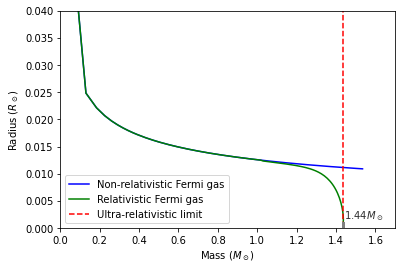

In [277]:
plt.plot(fm_nr_nu, fr_nr_nu, color="blue", label="Non-relativistic Fermi gas")
plt.plot(fm_rrel_nu, fr_rrel_nu, color="green", label="Relativistic Fermi gas")
plt.plot(fm_rel_nu, fr_rel_nu, color="red", label="Ultra-relativistic limit", linestyle="dashed")
#plt.plot(vm_nu, vr_nu, color="black", marker=".")
#plt.plot(v2m_nu, v2r_nu, color="black", marker=".")
plt.legend()
#plt.title("Radius-Mass Relation")
plt.xlabel("Mass " r"(${M_\odot}$)")
plt.ylabel("Radius " r"(${R_\odot}$)")
plt.text(1.54, 0.001, r"${1.44M_\odot}$", fontsize=10, color='#2f2f2f', ha='center', va='bottom')
x_pos = 1.435
plt.plot([x_pos, x_pos], [-0.1, 0.001], color='grey', lw=3) 
plt.xlim(0, 1.7)
plt.ylim(0, 0.04)
plt.show()

In [229]:
# only few changes #
final_masses_rrel = []
final_r_rrel = []

number = np.arange(0, num_cd)
count = np.linspace(0, 1, num_cd)

def interp(nr, rel, t):
    return (1 - t) * nr + t * rel

for a in number:
    c_d = c_densities[a]
#    print(f"Iteration {a}: c_d = {c_d}") 
    kf = k_f(c_d)
    n = count[a]
    ratio = kf/(m_e*c)
#    limit_v = 2e-22
    #if 10**7 < c_d < 10**13:
 #       print("yes")
  #      print(c_d)
#        m_add = final_masses_nr[a]
 #       r_add = final_r_nr[a]
#        print(m_add)
 #       print(r_add)
#    final_masses_rrel.append(m_add)
 #   final_r_rrel.append(r_add)
    if c_d < 10**10:
        nr11 = final_masses_nr[a]
        nr21 = final_r_nr[a]
        rel11 = final_masses_rel[a]
        rel21 = final_r_rel[a]
        if ratio < 3:
            m_add = nr11
            r_add = nr21
        elif ratio > 3:
            m_add = rel11
            r_add = rel21
        else:
            t = (kf - (m_e*c-limit_v)) / ((m_e*c + limit_v) - (m_e*c-limit_v))
            m_add = interp(nr11, rel11, t)
            r_add = interp(nr21, rel21, t)
        final_masses_rrel.append(m_add)
        final_r_rrel.append(r_add)
    else:
        rel12 = final_masses_rel[a]
        rel22 = final_r_rel[a]
        final_masses_rrel.append(rel12)
        final_r_rrel.append(rel22)
    